# Temperature cross-section along a line

A vertical cross-section shows how a quantity changes with height along a line over the Earth's surface. In this tutorial we plot the temperature along a line from (40°N, 10°W) to (56°N, 10°E).

This feature is **experimental**. For a more detailed version of this example, see [the high-level notebook](../high/cross_section.ipynb).

## Imports

First we import the tools we need.

In [1]:
import sys
from datetime import datetime, timedelta

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import cross_section

## Get the data

We load a small sample file and pick the temperature (`t`) for one date and forecast step.

In [2]:
ds = ekd.from_source("sample", "xs_pl_input.grib1").to_fieldlist()

base_date = datetime(2011, 12, 15, 12)
step = timedelta(hours=12)

t = ds.sel({"parameter.variable": "t", "time.base_datetime": base_date, "time.step": step})

xs_pl_input.grib1:   0%|          | 0.00/61.5k [00:00<?, ?B/s]

## Define the line

We choose 200 evenly spaced points along the line from (40°N, 10°W) to (56°N, 10°E).

In [3]:
lats, lons = sample_polyline([40, 56], [-10, 10], n=200)

## Compute the cross-section

Now we compute the values of the temperature at the points of the line. Log messages may appear while this runs; you can ignore them.

In [4]:
xs = cross_section(t, lats, lons)
xs

Error setting gridSpec={"type": "unstructured_ll", "uid": "af921c9cb9ccab2a0eaeabad3f534da6"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

<xarray.Dataset> Size: 14kB
Dimensions:                  (level: 6, distance: 200)
Coordinates:
  * level                    (level) int64 48B 300 400 500 700 850 1000
  * distance                 (distance) float64 2kB 0.0 11.57 ... 2.302e+03
    latitude                 (distance) float64 2kB 40.0 40.09 ... 55.93 56.0
    longitude                (distance) float64 2kB -10.0 -9.926 ... 9.862 10.0
    forecast_reference_time  datetime64[ns] 8B 2011-12-15T12:00:00
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    t                        (level, distance) float64 10kB 234.2 ... 276.3
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Plot the cross-section

We draw the temperature with the pressure on the vertical axis, from 1000 hPa at the bottom to 300 hPa at the top, and label the axes with the positions along the line.

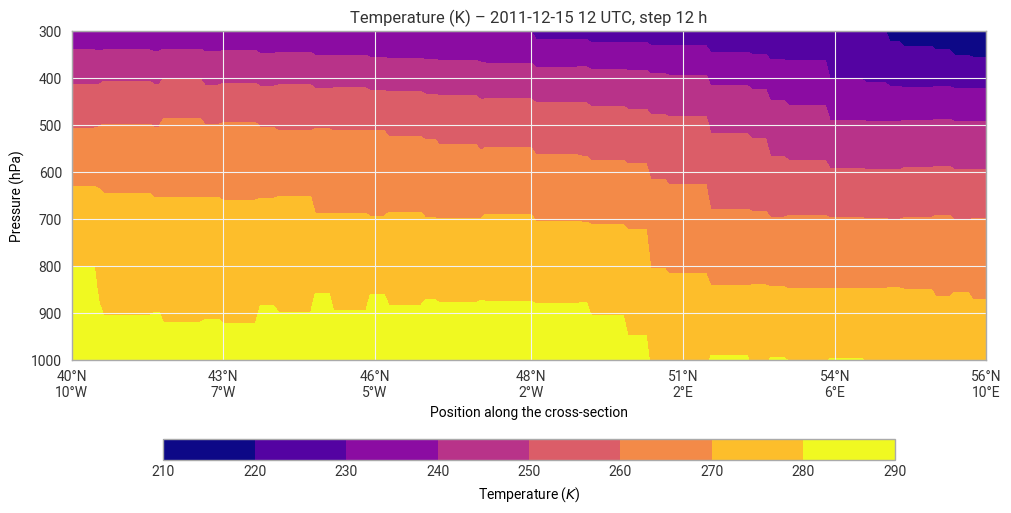

In [5]:
def fmt_lat(lat):
    lat = int(round(lat))
    return f"{abs(lat)}°N" if lat > 0 else f"{abs(lat)}°S" if lat < 0 else "0°"


def fmt_lon(lon):
    lon = int(round(lon))
    return f"{abs(lon)}°E" if lon > 0 else f"{abs(lon)}°W" if lon < 0 else "0°"


# 7 evenly spaced points along the line
idx = np.linspace(0, len(lats) - 1, 7).round().astype(int)
tick_labels = [f"{fmt_lat(lats[i])}\n{fmt_lon(lons[i])}" for i in idx]

chart = ekp.Subplot(figsize=(10, 5))
chart.contourf(xs["t"], x="distance", y="level")
chart.figure.legend()

ax = chart.ax
ax.invert_yaxis()  # 1000 hPa at the bottom, 300 hPa at the top
ax.set_xticks(xs["distance"].values[idx])
ax.set_xticklabels(tick_labels)
ax.set_xlabel("Position along the cross-section")
ax.set_ylabel("Pressure (hPa)")
ax.set_title(f"Temperature (K) – {base_date:%Y-%m-%d %H} UTC, step {step.total_seconds() / 3600:g} h")

chart.show()